In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
private_test = pd.read_csv('/kaggle/input/datasets/navamikhatmode/e-commerce-conversion-prediction/private_test.csv')


In [3]:
public_test = pd.read_csv('/kaggle/input/datasets/navamikhatmode/e-commerce-conversion-prediction/public_test.csv')

In [4]:
train = pd.read_csv('/kaggle/input/datasets/navamikhatmode/e-commerce-conversion-prediction/train.csv')

In [5]:
train.head()

,User_ID,Age,Income,City_Tier,Device_Type,Traffic_Source,Pages_Viewed,Products_Viewed,Time_On_Site,Previous_Purchases,Discount_Seen,Browser_Version,Campaign_Code,Converted
0,1,58.0,103593.708812,2,Mobile,Organic,5,4,9.61,3,0,11,2418,0
1,2,26.0,36451.716984,2,Mobile,Social Media,11,3,17.63,2,0,14,1213,0
2,3,19.0,30511.228700,3,Mobile,Referral,1,1,13.25,5,0,5,2849,0
3,4,48.0,87789.172342,3,Mobile,Email,14,12,NaN,1,1,19,7610,0
4,5,35.0,105229.249067,2,Mobile,Social Media,14,21,16.92,1,0,5,9261,0


In [6]:
private_test.head()

,User_ID,Age,Income,City_Tier,Device_Type,Traffic_Source,Pages_Viewed,Products_Viewed,Time_On_Site,Previous_Purchases,Discount_Seen,Browser_Version,Campaign_Code
0,103001,54.0,12000.000000,2,Mobile,Email,3,1,13.14,3,0,9,3685
1,103002,59.0,NaN,3,Mobile,Organic,22,20,NaN,4,0,18,9612
2,103003,NaN,79296.908337,2,Mobile,Paid Ads,28,24,3.36,1,0,2,4522
3,103004,19.0,65279.025663,2,Mobile,Social Media,20,13,8.78,6,1,5,4623
4,103005,31.0,NaN,3,Mobile,Paid Ads,10,15,24.14,5,0,20,8663


In [7]:
public_test.head()

,User_ID,Age,Income,City_Tier,Device_Type,Traffic_Source,Pages_Viewed,Products_Viewed,Time_On_Site,Previous_Purchases,Discount_Seen,Browser_Version,Campaign_Code,Converted
0,100001,50.0,65922.413596,3,Tablet,Organic,15,16,NaN,2,0,13,5698,1
1,100002,39.0,43205.865640,1,Mobile,Paid Ads,17,16,12.72,2,1,10,7011,0
2,100003,NaN,44333.908253,3,Mobile,Organic,17,15,3.13,5,0,21,8265,1
3,100004,22.0,141906.816221,3,Desktop,Social Media,1,2,25.32,3,0,9,5592,0
4,100005,47.0,39521.673456,1,Mobile,Social Media,2,4,NaN,3,1,9,4128,0


# EDA

In [8]:
print("Train data shape:",train.shape)
print("Public test shape:",public_test.shape)
print("Private test shape:",private_test.shape)

Train data shape: (10000, 14)
Public test shape: (3000, 14)
Private test shape: (3000, 13)


In [9]:
missing_train = train.isnull().sum().sum()/100
missing_public = public_test.isnull().sum().sum()/100
missing_private = private_test.isnull().sum().sum()/100
print("missing %:")
print(missing_train)
print(missing_public)
print(missing_private)

missing %:
43.12
13.41
13.25


In [10]:
missing_train = train.isnull().sum()/100
print(missing_train)

User_ID                0.00
Age                   14.80
Income                 9.84
City_Tier              0.00
Device_Type            0.00
Traffic_Source         0.00
Pages_Viewed           0.00
Products_Viewed        0.00
Time_On_Site          18.48
Previous_Purchases     0.00
Discount_Seen          0.00
Browser_Version        0.00
Campaign_Code          0.00
Converted              0.00
dtype: float64


In [11]:
missing_public = public_test.isnull().sum()/100
print(missing_public)

User_ID               0.00
Age                   4.72
Income                3.01
City_Tier             0.00
Device_Type           0.00
Traffic_Source        0.00
Pages_Viewed          0.00
Products_Viewed       0.00
Time_On_Site          5.68
Previous_Purchases    0.00
Discount_Seen         0.00
Browser_Version       0.00
Campaign_Code         0.00
Converted             0.00
dtype: float64


In [12]:
missing_private = private_test.isnull().sum()/100
print(missing_private)

User_ID               0.00
Age                   4.61
Income                3.02
City_Tier             0.00
Device_Type           0.00
Traffic_Source        0.00
Pages_Viewed          0.00
Products_Viewed       0.00
Time_On_Site          5.62
Previous_Purchases    0.00
Discount_Seen         0.00
Browser_Version       0.00
Campaign_Code         0.00
dtype: float64


In [13]:
# The methods that can be used to fill the missing information 
# Delete that particular row
# Use imputation - mean, median etc
# grouped by imputation, KNN, MICE etc
# BUT,the model that is being used for the final training is going to be- XGBoost
# And, XGBoost handles numerical missing data very well on its own

In [14]:
# Analysing the imbalance in the ouput column
Count = train['Converted'].value_counts(normalize = True)*100
print(Count)

Converted
0    69.13
1    30.87
Name: proportion, dtype: float64


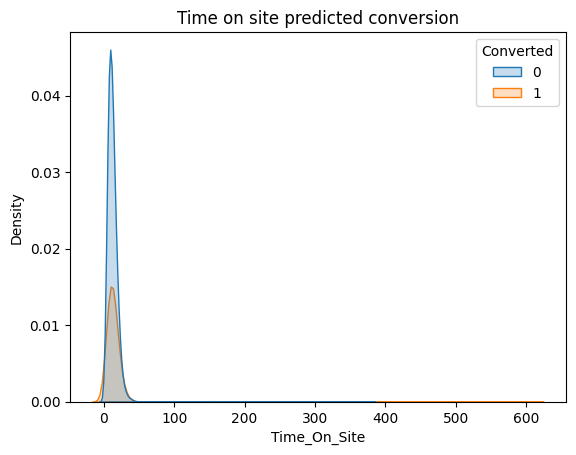

In [15]:
# Density plots for features like  
# Time_On_Site, Age, Income
sns.kdeplot(data = train, x = 'Time_On_Site', hue = 'Converted', fill = True)
plt.title('Time on site predicted conversion')
plt.show()

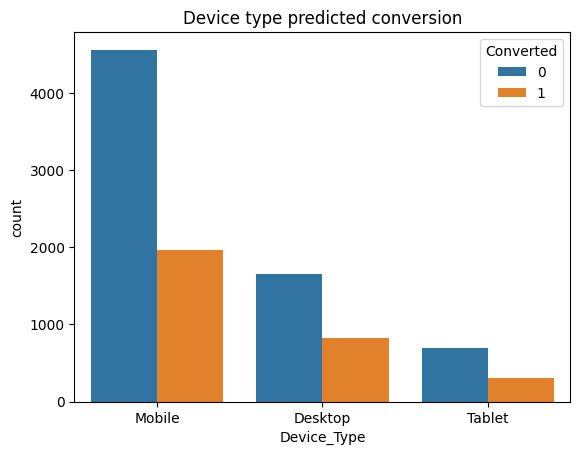

In [16]:
sns.countplot(data = train,x='Device_Type', hue = 'Converted')
plt.title('Device type predicted conversion')
plt.show()

Clearly people using mobile very more likely to be converted

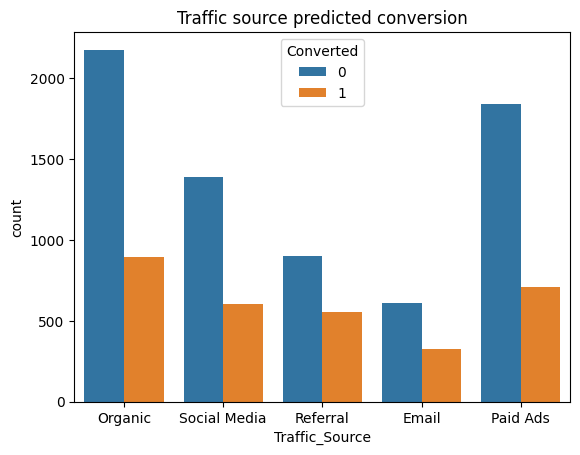

In [17]:
sns.countplot(data = train,x='Traffic_Source', hue = 'Converted')
plt.title('Traffic source predicted conversion')
plt.show()

The organic traffic source gave highest conversion

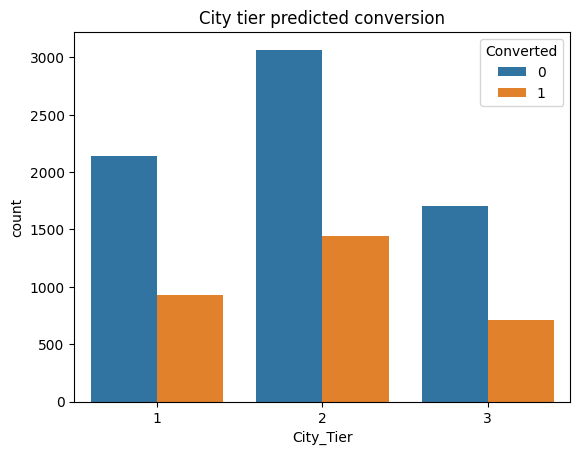

In [18]:
sns.countplot(data = train,x='City_Tier', hue = 'Converted')
plt.title('City tier predicted conversion')
plt.show()

Tier 2 cities gave highest conversion

In [19]:
# Check for collinearity between feature
# If two features are highly correlated then
# Either we need any of them or ratio of them

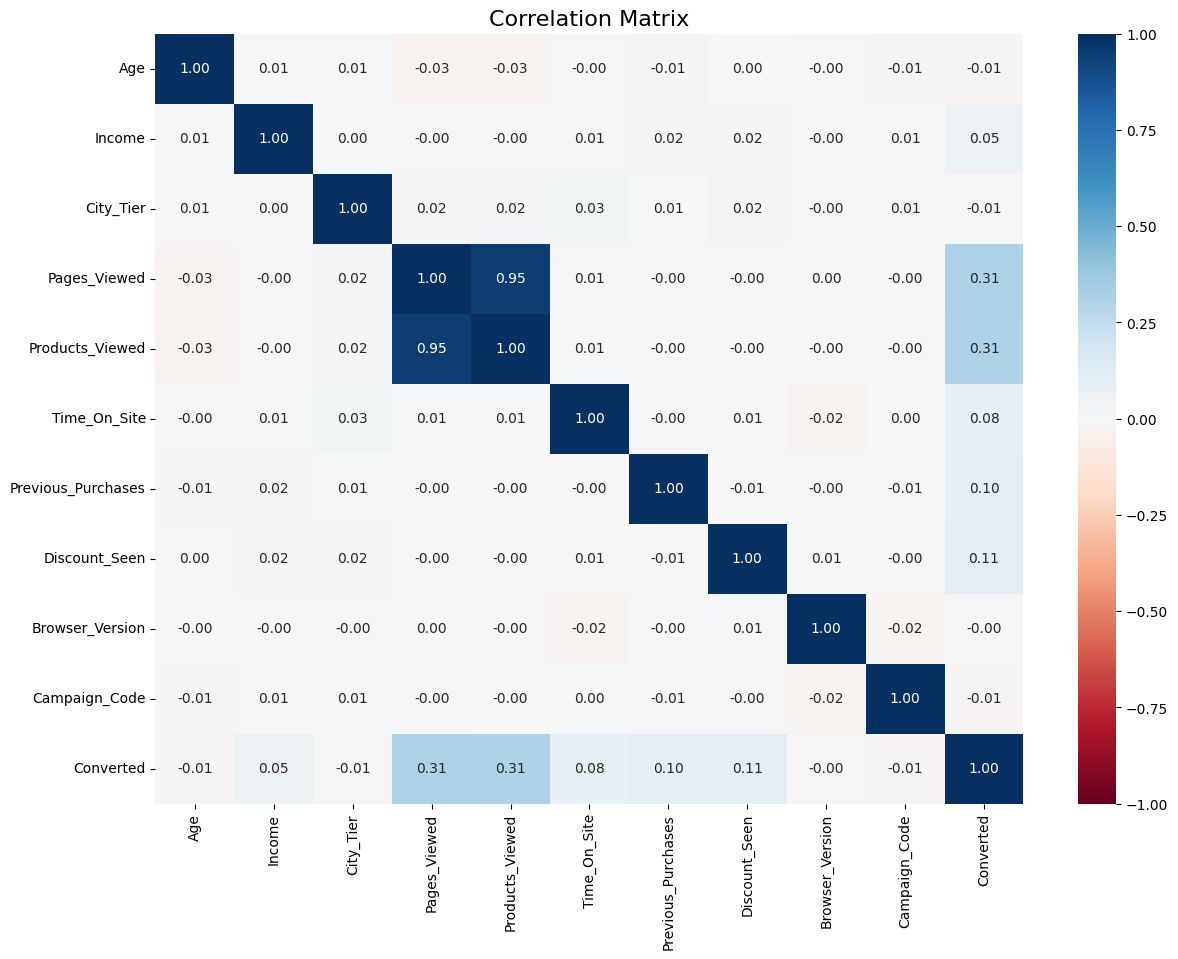

In [20]:
numerical_train = train.select_dtypes(include=['int64','float64']).drop(columns = 'User_ID', errors = 'ignore')

plt.figure(figsize= (14,10))
sns.heatmap(numerical_train.corr(),annot=True,cmap = 'RdBu',fmt = '.2f',vmin = -1,vmax = 1)
plt.title('Correlation Matrix', fontsize = 16)
plt.show()

# Feature Engineering & Data Preprocessing

In [21]:
# Categorical encoding - using out-of-fold target encoding
# At the missing places for categorical column - fill in as unkown
# User_ID is the least important feature and may lead to overfitting- hence removed

In [22]:
from sklearn.model_selection import KFold

y_train = train['Converted']
X_train = train.drop(columns=['User_ID', 'Converted'], errors='ignore')
X_public = public_test.drop(columns=['User_ID', 'Converted'], errors='ignore')
X_private = private_test.drop(columns=['User_ID', 'Converted'], errors='ignore')

In [23]:
# Filling missing values in categorical column
categorical_cols = ['Device_Type', 'Traffic_Source']

for df in [X_train, X_public, X_private]:
    df[categorical_cols] = df[categorical_cols].fillna('Unkown')


In [24]:
# Frequency encoding for campaign code
# The frequency is calculated only on training set to prevent data leakage
campaign_freq = X_train['Campaign_Code'].value_counts(normalize=True)


for df in [X_train, X_public, X_private]:
    df['Campaign_Code_Freq'] = df['Campaign_Code'].map(campaign_freq)
    
    df['Campaign_Code_Freq'] = df['Campaign_Code_Freq'].fillna(0)
    
   
    df.drop(columns=['Campaign_Code'], inplace=True)

In [25]:
# Using one hot encoding
X_train_final = pd.get_dummies(X_train,columns = categorical_cols,drop_first = True)
X_public_final = pd.get_dummies(X_public,columns = categorical_cols, drop_first = True)
X_private_final = pd.get_dummies(X_private, columns = categorical_cols, drop_first = True)

In [26]:
for df in [X_train_final, X_public_final, X_private_final]:
    # Average time spent per page viewed
    df['Time_Per_Page'] = df['Time_On_Site'] / (df['Pages_Viewed'] + 1e-5)
    
    df['Product_Ratio'] = df['Products_Viewed'] / (df['Pages_Viewed'] + 1e-5)

In [27]:
# Adding missing flag
for df in [X_train_final, X_public_final, X_private_final]:
    df['Time_On_Site_Missing'] = df['Time_On_Site'].isnull().astype(int)
    df['Age_Missing'] = df['Age'].isnull().astype(int)

In [28]:
for df in [X_train_final, X_public_final, X_private_final]:
    # 1. Is this a loyal user who is also getting a discount? (High conversion probability)
    df['Loyal_Discounted'] = df['Previous_Purchases'] * df['Discount_Seen']
    
    # 2. Page views adjusted by historical trust
    df['Trust_Engagement'] = (df['Previous_Purchases'] + 1) * df['Pages_Viewed']

In [29]:
# Droping Browser_Version across all final datasets
for df in [X_train_final, X_public_final, X_private_final]:
    df.drop(columns=['Browser_Version'], inplace=True, errors='ignore')

In [30]:
X_train_final.head()

,Age,Income,City_Tier,Pages_Viewed,Products_Viewed,Time_On_Site,Previous_Purchases,Discount_Seen,Campaign_Code_Freq,Device_Type_Mobile,...,Traffic_Source_Organic,Traffic_Source_Paid Ads,Traffic_Source_Referral,Traffic_Source_Social Media,Time_Per_Page,Product_Ratio,Time_On_Site_Missing,Age_Missing,Loyal_Discounted,Trust_Engagement
0,58.0,103593.708812,2,5,4,9.61,3,0,0.0001,True,...,True,False,False,False,1.921996,0.799998,0,0,0,20
1,26.0,36451.716984,2,11,3,17.63,2,0,0.0002,True,...,False,False,False,True,1.602726,0.272727,0,0,0,33
2,19.0,30511.228700,3,1,1,13.25,5,0,0.0003,True,...,False,False,True,False,13.249868,0.999990,0,0,0,6
3,48.0,87789.172342,3,14,12,NaN,1,1,0.0002,True,...,False,False,False,False,NaN,0.857142,1,0,1,28
4,35.0,105229.249067,2,14,21,16.92,1,0,0.0001,True,...,False,False,False,True,1.208571,1.499999,0,0,0,28


In [31]:
X_train_final.shape

(10000, 21)

# Model (XGBoost)

In [32]:
from xgboost import XGBClassifier
from sklearn.metrics import f1_score, classification_report, roc_auc_score


baseline_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    scale_pos_weight=2.24,
    random_state=42,
    eval_metric='logloss'
)


baseline_model.fit(X_train_final, y_train)


y_train_pred = baseline_model.predict(X_train_final)
y_train_proba = baseline_model.predict_proba(X_train_final)[:, 1]


f1 = f1_score(y_train, y_train_pred)
roc_auc = roc_auc_score(y_train, y_train_proba)

print("--- Baseline Model Performance (Train Set) ---")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print("\nDetailed Classification Report:")
print(classification_report(y_train, y_train_pred))

--- Baseline Model Performance (Train Set) ---
F1-Score:  0.6622
ROC-AUC:   0.8558

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.71      0.79      6913
           1       0.56      0.81      0.66      3087

    accuracy                           0.74     10000
   macro avg       0.73      0.76      0.73     10000
weighted avg       0.79      0.74      0.75     10000



In [33]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, f1_score

X = X_train_final
y = y_train


# 1. Split into training and validation sets
X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 2. Initialize the model
model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    scale_pos_weight=2.24,
    random_state=42,
    eval_metric='logloss',
    colsample_bytree=0.8,
    reg_lambda = 1
    
)

# 3. Fit the model
model.fit(X_train_split, y_train_split)

# 4. Predict on validation set
y_val_pred = model.predict(X_val_split)

# 5. Evaluate performance
print("--- Validation Set Performance ---")
print(f"Validation F1-Score: {f1_score(y_val_split, y_val_pred):.4f}")
print("\nClassification Report:\n", classification_report(y_val_split, y_val_pred))

--- Validation Set Performance ---
Validation F1-Score: 0.5561

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.66      0.73      1383
           1       0.47      0.68      0.56       617

    accuracy                           0.67      2000
   macro avg       0.65      0.67      0.64      2000
weighted avg       0.71      0.67      0.68      2000



In [34]:
#Changing the threshold from 0.5 to some other value

from sklearn.metrics import f1_score
y_val_proba = model.predict_proba(X_val_split)[:, 1]

best_threshold = 0.5
best_f1 = 0

for threshold in np.arange(0.1, 0.9, 0.01):
    preds = (y_val_proba >= threshold).astype(int)
    score = f1_score(y_val_split, preds)
    if score > best_f1:
        best_f1 = score
        best_threshold = threshold

print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximized Validation F1-Score: {best_f1:.4f}")

Best Threshold: 0.42
Maximized Validation F1-Score: 0.5741


In [35]:
# predicting on the public dataset
y_public_proba = model.predict_proba(X_public_final)[:, 1]

y_public_pred = (y_public_proba >= 0.44).astype(int)

y_public_true = public_test['Converted']
public_f1 = f1_score(y_public_true, y_public_pred)

print(f"Public Test Set F1-Score: {public_f1:.4f}")

Public Test Set F1-Score: 0.5413


## Learning Curve

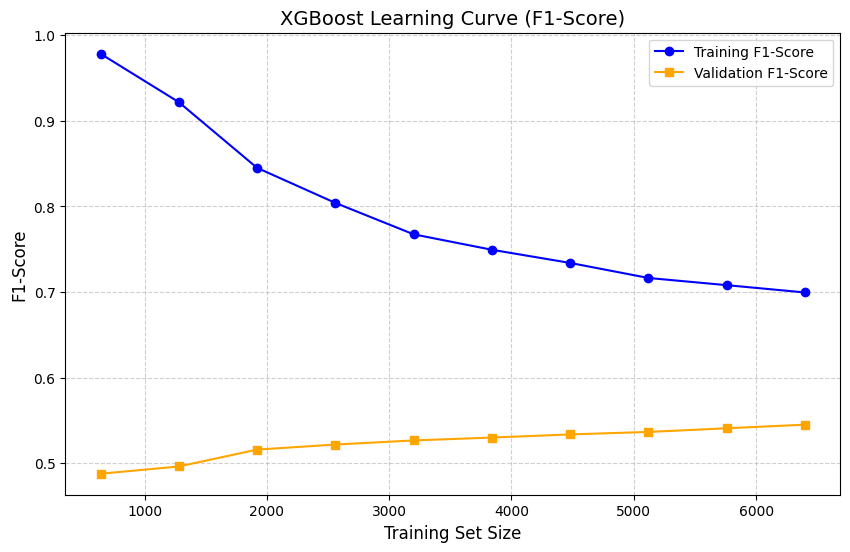

In [36]:
from sklearn.model_selection import learning_curve

train_sizes = np.linspace(0.1, 1.0, 10)
train_sizes_out, train_scores, val_scores = learning_curve(
    estimator=model,
    X=X_train_split,
    y=y_train_split,
    train_sizes=train_sizes,
    cv=5,                  
    scoring='f1',
    n_jobs=-1              
)
train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

# Plotting the learning curve
plt.figure(figsize=(10, 6))
plt.plot(train_sizes_out, train_mean, label='Training F1-Score', color='blue', marker='o')
plt.plot(train_sizes_out, val_mean, label='Validation F1-Score', color='orange', marker='s')

plt.title('XGBoost Learning Curve (F1-Score)', fontsize=14)
plt.xlabel('Training Set Size', fontsize=12)
plt.ylabel('F1-Score', fontsize=12)
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [37]:
predictions = model.predict(X_private_final)
submission = pd.DataFrame(
    {
        "User_ID" : private_test['User_ID'],
        "Converted" : predictions
    }
)
submission.to_csv("submission.csv", index=False)

print("submission.csv created successfully!")
submission.head(3000)


submission.csv created successfully!


,User_ID,Converted
0,103001,0
1,103002,0
2,103003,1
3,103004,1
4,103005,0
...,...,...
2995,105996,0
2996,105997,0
2997,105998,1
2998,105999,1


In [38]:
# 1. Clean install only the light tabular components of AutoGluon
!pip install autogluon.tabular -q

from autogluon.tabular import TabularPredictor
import pandas as pd

# 2. Reconstruct the training and validation dataframes
train_data = X_train_split.copy()
train_data['Converted'] = y_train_split

val_data = X_val_split.copy()
val_data['Converted'] = y_val_split

# 3. Initialize and fit the predictor (using 'medium_quality' to be safe and fast)
predictor = TabularPredictor(
    label='Converted', 
    eval_metric='f1'
).fit(
    train_data=train_data, 
    tuning_data=val_data, 
    presets='medium_quality'
)

# 4. Evaluate performance on your Validation Set
performance = predictor.evaluate(val_data)
print("\n--- AutoGluon Validation Performance ---")
print(performance)

# 5. See which models performed the best
leaderboard = predictor.leaderboard(val_data, silent=False)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 515.2/515.2 kB 11.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 227.6/227.6 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.9/98.9 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.4/74.4 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 76.8 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 MB 42.3 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
datasets 4.8.5 requires pyarrow>=21.0.0, but you have pyar

No path specified. Models will be saved in: "AutogluonModels/ag-20260618_085535"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.13
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Sat May 30 15:40:53 UTC 2026
CPU Count:          4
Pytorch Version:    2.10.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       29.33 GB / 31.35 GB (93.5%)
Disk Space Avail:   19.50 GB / 19.52 GB (99.9%)
Presets specified: ['medium_quality']
Using hyperparameters preset: hyperparameters='default'
Beginning AutoGluon training ...
AutoGluon will save models to "/kaggle/working/AutogluonModels/ag-20260618_085535"
Train Data Rows:    8000
Train Data Columns: 21
Tuning Data Rows:    2000
Tuning Data Columns: 21
Label Column:       Converted
AutoGluon infers your prediction problem is: 'binary' (because only two unique label-values observed).
	2 unique label values:  [np.int64(1), n


--- AutoGluon Validation Performance ---
{'f1': 0.5682087781731909, 'accuracy': 0.636, 'balanced_accuracy': np.float64(0.6748641468350929), 'mcc': np.float64(0.3238327351129394), 'roc_auc': np.float64(0.7206645642678929), 'precision': 0.44808231992516373, 'recall': 0.7763371150729336}
                 model  score_test  score_val eval_metric  pred_time_test  pred_time_val   fit_time  pred_time_test_marginal  pred_time_val_marginal  fit_time_marginal  stack_level  can_infer  fit_order
0  WeightedEnsemble_L2    0.568209   0.562628          f1        0.199192       0.168468  13.199194                 0.002505                0.002917           0.483253            2       True          9
1      NeuralNetFastAI    0.560446   0.561426          f1        0.042994       0.045448   9.917604                 0.042994                0.045448           9.917604            1       True          6
2       NeuralNetTorch    0.533231   0.487336          f1        0.023484       0.019215  15.753943     